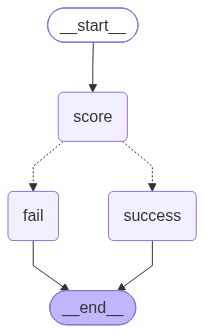

In [2]:
from langgraph.types import Command
from typing import TypedDict, Literal
from IPython.display import Image, display
from langgraph.constants import START, END
from langgraph.graph import StateGraph


# ============1.State=================
class ScoreState(TypedDict):
    score: int
    result: str


# ============2.Node=================
def score_node(state: ScoreState) -> Command[Literal["success", "fail"]]:
    # 键盘录入用户分数
    score = int(input("请输入用户分数:"))

    # 判断下个节点
    goto = "fail"
    if score >= 60:
        goto = "success"

    # 返回中做两件事：1.返回下个节点名称，2，更新State
    return Command(
        update={"score": score},  # 更新State
        goto=goto  # 下个节点名称
    )


def success_node(state: ScoreState):
    return {"result": "恭喜，考试通过！"}


def fail_node(state: ScoreState):
    return {"result": "节哀，考试没通过！"}


# ============3.Edge连接Node，形成Graph=================
builder = StateGraph(ScoreState)

builder.add_node("score", score_node)
builder.add_node("success", success_node)
builder.add_node("fail", fail_node)

builder.add_edge(START, "score")
builder.add_edge("success", END)
builder.add_edge("fail", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [4]:
# ============4.调用Graph=================
result = graph.invoke({})

print(result)

{'score': 56, 'result': '节哀，考试没通过！'}
